# Parte 5. Análisis de robustez

**Resultados de la S1 que se ponen a prueba:** medias de la Tabla 5, diferencias de medias de la Tabla 4
(presión sistólica y glucosa), prueba de tabaquismo de la sección 4.2, correlaciones de Spearman de la
sección 2.2 y decisiones de limpieza de la Tabla 1 (imputación de `cigsPerDay` con la mediana de fumadores
= 20, casos disponibles para glucosa, atípicos conservados como el colesterol de 696 mg/dL y la glucosa de
394 mg/dL).

**Estrategia.** Cada resultado de la S1 se somete a cuatro tipos de perturbación:

1. **Influencia individual (jackknife):** cuánto cambia el estimador al quitar una observación.
2. **Tratamiento de atípicos:** excluir atípicos de Tukey, recortar colas (media recortada al 5 %), usar la
   mediana con IC BCa, estimadores menos afectados por valores extremos.
3. **Supuestos y limpieza:** Pearson vs Spearman, estrategias de imputación, ruido de medición
   (perturbación X + N(0, (δ·s)²)) y distribuciones alternativas (normal,
   lognormal, empírica y contaminada) para evaluar sesgo, ECM y cobertura.
4. **Análisis OAT y tornado:** cada decisión se cambia de a una y se
   ordena según su impacto.

**Regla de clasificación:**
cambio relativo < 10 % y misma decisión inferencial → **Robusto**; cambio ≥ 10 % sin cambio de decisión →
**Requiere cautela**; la decisión cambia (el p cruza 0,05 o el IC pasa a incluir 0) → **Sensible**.

## Configuración

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.contingency_tables import StratifiedTable

from utils_s2 import (
    SEED, B, ALPHA, RESULTADOS_S1, NOMBRES, NUM, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    ic_bootstrap, p_valor_permutacion, jackknife, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | Variables: 16 | B = 10,000 | semilla = 42


In [2]:
# Los datos deben reproducir las cifras de la S1
assert round(df["age"].mean(), 2) == RESULTADOS_S1["ic"]["edad_media"]["estimacion"]
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["totChol"].mean(), 2) == RESULTADOS_S1["ic"]["colesterol_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


### Funciones de apoyo

In [3]:
VARIABLES = ["age", "sysBP", "totChol", "glucose"]          # medias de la Tabla 5 + glucosa (caso asimétrico)
CLAVE_S1 = {"age": "edad_media", "sysBP": "sysbp_media", "totChol": "colesterol_media"}
chd = df["TenYearCHD"].to_numpy(int)


def limites_tukey(s):
    # Límites de Tukey [Q1 - 1,5·IQR, Q3 + 1,5·IQR], el mismo criterio de la S1
    q1, q3 = np.nanpercentile(s, [25, 75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def es_atipico(s):
    inf, sup = limites_tukey(s)
    return (s < inf) | (s > sup)


def media_recortada(x, axis=-1):
    return stats.trim_mean(x, 0.05, axis=axis)


def ic_bca(x, estadistico, seed):
    # IC BCa con scipy.stats.bootstrap por lotes (evita matrices de 10.000 × n en memoria).
    # Si BCa no es calculable (p. ej. mediana de datos enteros: todos los leave-one-out son iguales y la
    # aceleración queda indeterminada), se usa el IC percentil con las mismas remuestras.
    opciones = dict(n_resamples=B, vectorized=True, batch=500)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = stats.bootstrap((np.asarray(x, float),), estadistico, method="BCa",
                              random_state=np.random.default_rng(seed), **opciones)
    if np.isnan(res.confidence_interval.low):
        res = stats.bootstrap((np.asarray(x, float),), estadistico, method="percentile",
                              random_state=np.random.default_rng(seed), **opciones)
        print(f"  BCa no calculable para {estadistico.__name__}; se usa percentil")
    return res.confidence_interval.low, res.confidence_interval.high


def ic_t(x):
    x = np.asarray(x, float)
    return stats.t.interval(1 - ALPHA, len(x) - 1, loc=x.mean(), scale=stats.sem(x))


def welch(x1, x0):
    # Diferencia de medias, IC de Welch, p y d de Cohen (como en la S1)
    t = stats.ttest_ind(x1, x0, equal_var=False)
    ic = t.confidence_interval(1 - ALPHA)
    n1, n0 = len(x1), len(x0)
    sp = np.sqrt(((n1 - 1) * np.var(x1, ddof=1) + (n0 - 1) * np.var(x0, ddof=1)) / (n1 + n0 - 2))
    return {"dif": np.mean(x1) - np.mean(x0), "ic_inf": ic.low, "ic_sup": ic.high,
            "t": t.statistic, "p": t.pvalue, "d": (np.mean(x1) - np.mean(x0)) / sp, "n1": n1, "n0": n0}


def grupos(variable, datos=df):
    d = datos[[variable, "TenYearCHD"]].dropna()
    return (d.loc[d["TenYearCHD"] == 1, variable].to_numpy(float),
            d.loc[d["TenYearCHD"] == 0, variable].to_numpy(float))


def cambio_pct(nuevo, base):
    return 100 * (nuevo - base) / abs(base)

## 5.1 Jackknife e influencia

El jackknife recalcula el estimador *n* veces dejando fuera una observación cada vez (θ̂₍ᵢ₎). Con esos
valores se estiman el sesgo y el error estándar, y la **influencia** de cada observación: cuánto cambia el
estimador cuando se excluye. Los mismos valores leave-one-out definen la **aceleración** `a` del BCa,
a = Σ(θ̄ − θ̂₍ᵢ₎)³ / [6 (Σ(θ̄ − θ̂₍ᵢ₎)²)^(3/2)]. Una aceleración alejada de 0 indica que la distribución del estimador es asimétrica y
explica por qué el BCa se separa del IC simétrico de Welch (hallazgo del bloque A para la glucosa).

Para la media, el jackknife reproduce exactamente el error estándar clásico s/√n y su sesgo es 0, así que su
aporte está en la influencia y en `a`. No se aplica a la media recortada ni a la mediana: son estimadores **no
suaves** (al quitar una observación cambia de forma discreta cuántos valores se recortan o cuál es el valor
central) y el jackknife entrega sesgos y EE poco confiables para ellos.
Para esos estimadores se usa bootstrap BCa en 5.2.

In [4]:
def aceleracion(loo):
    d = loo.mean() - loo
    return np.sum(d**3) / (6 * np.sum(d**2) ** 1.5)


filas_jk, jk_media = [], {}
for v in VARIABLES:
    x = df[v].dropna().to_numpy(float)
    jm = jackknife(x, np.mean)
    jk_media[v] = jm
    filas_jk.append({
        "Variable": NOMBRES[v], "n": len(x), "Media": jm["estimacion"],
        "EE clásico (s/√n)": stats.sem(x), "EE jackknife": jm["ee"],
        "Sesgo jackknife": jm["sesgo"], "Aceleración a": aceleracion(jm["loo"]),
        "Asimetría muestral": stats.skew(x),
        "Máx. |cambio| al quitar 1 obs.": np.max(np.abs(jm["loo"] - jm["estimacion"])),
    })
tabla_jk = pd.DataFrame(filas_jk).set_index("Variable")
guardar_tabla(tabla_jk.round(4), "p5_jackknife")

,n,Media,EE clásico (s/√n),EE jackknife,Sesgo jackknife,Aceleración a,Asimetría muestral,Máx. |cambio| al quitar 1 obs.
Variable,,,,,,,,
Edad (años),4240,49.5802,0.1317,0.1317,0.0000,0.0006,0.2288,0.0048
Presión sistólica (mmHg),4240,132.3546,0.3384,0.3384,0.0000,0.0029,1.1449,0.0384
Colesterol total (mg/dL),4190,236.6995,0.6889,0.6889,0.0000,0.0022,0.8716,0.1096
Glucosa (mg/dL),3852,81.9637,0.3860,0.3860,0.0000,0.0167,6.2125,0.0810


**Influencia sobre las diferencias de medias de la Tabla 4.** Para una diferencia entre grupos, quitar la
observación *i* solo cambia la media de su grupo, así que los valores leave-one-out se calculan en forma
cerrada (sin recorrer 4.240 recálculos).

In [5]:
def jackknife_diferencia(x1, x0):
    # Valores leave-one-out de mean(x1) - mean(x0), en el orden [x1..., x0...]
    loo1 = (x1.sum() - x1) / (len(x1) - 1) - x0.mean()
    loo0 = x1.mean() - (x0.sum() - x0) / (len(x0) - 1)
    return np.concatenate([loo1, loo0])


filas_inf, jk_dif = [], {}
for v in ["sysBP", "glucose"]:
    x1, x0 = grupos(v)
    theta = x1.mean() - x0.mean()
    loo = jackknife_diferencia(x1, x0)
    n = len(loo)
    ee = np.sqrt((n - 1) / n * np.sum((loo - loo.mean()) ** 2))
    jk_dif[v] = {"theta": theta, "loo": loo, "valores": np.concatenate([x1, x0]),
                 "grupo": np.r_[np.ones(len(x1)), np.zeros(len(x0))], "ee": ee, "a": aceleracion(loo)}
    print(f"{NOMBRES[v]}: diferencia = {theta:.2f} | EE jackknife = {ee:.3f} | aceleración a = {aceleracion(loo):.4f}")

# Observaciones más influyentes por estimador
for v in VARIABLES:
    jm = jk_media[v]
    x = df[v].dropna()
    cambio = jm["estimacion"] - jm["loo"]               # cuánto baja la media al excluir la observación
    top = np.argsort(-np.abs(cambio))[:5]
    inf, sup = limites_tukey(x)
    for r, i in enumerate(top, 1):
        filas_inf.append({"Estimador": f"Media de {NOMBRES[v]}", "Ranking": r, "Fila": int(x.index[i]),
                          "Valor": x.iloc[i], "TenYearCHD": int(df.loc[x.index[i], "TenYearCHD"]),
                          "Cambio al excluir": -cambio[i], "Atípico Tukey": not (inf <= x.iloc[i] <= sup)})
for v in ["sysBP", "glucose"]:
    j = jk_dif[v]
    cambio = j["theta"] - j["loo"]
    top = np.argsort(-np.abs(cambio))[:5]
    inf, sup = limites_tukey(df[v])
    for r, i in enumerate(top, 1):
        filas_inf.append({"Estimador": f"Diferencia CHD − sin CHD de {NOMBRES[v]}", "Ranking": r, "Fila": np.nan,
                          "Valor": j["valores"][i], "TenYearCHD": int(j["grupo"][i]),
                          "Cambio al excluir": -cambio[i], "Atípico Tukey": not (inf <= j["valores"][i] <= sup)})
tabla_influyentes = pd.DataFrame(filas_inf).set_index(["Estimador", "Ranking"])
guardar_tabla(tabla_influyentes.round(4), "p5_influyentes")

Presión sistólica (mmHg): diferencia = 13.28 | EE jackknife = 1.106 | aceleración a = 0.0055
Glucosa (mg/dL): diferencia = 8.33 | EE jackknife = 1.722 | aceleración a = 0.0285


Fila  \
Estimador                                          Ranking              
Media de Edad (años)                               1       1,624.0000   
                                                   2       3,137.0000   
                                                   3       4,100.0000   
                                                   4       3,674.0000   
                                                   5       3,278.0000   
Media de Presión sistólica (mmHg)                  1         481.0000   
                                                   2       3,489.0000   
                                                   3         864.0000   
                                                   4       1,189.0000   
                                                   5       2,091.0000   
Media de Colesterol total (mg/dL)                  1       3,160.0000   
                                                   2       1,111.0000   
                                                   3         194.0000   
                                                   4       3,474.0000   
                                                   5         543.0000   
Media de Glucosa (mg/dL)                           1       2,893.0000   
                                                   2       2,909.0000   
                                                   3       2,406.0000   
                                                   4       3,971.0000   
                                                   5       3,844.0000   
Diferencia CHD − sin CHD de Presión sistólica (... 1              NaN   
                                                   2              NaN   
                                                   3              NaN   
                                                   4              NaN   
                                                   5              NaN   
Diferencia CHD − sin CHD de Glucosa (mg/dL)        1              NaN   
                                                   2              NaN   
                                                   3              NaN   
                                                   4              NaN   
                                                   5              NaN   

                                                              Valor  \
Estimador                                          Ranking            
Media de Edad (años)                               1        70.0000   
                                                   2        70.0000   
                                                   3        69.0000   
                                                   4        69.0000   
                                                   5        69.0000   
Media de Presión sistólica (mmHg)                  1       295.0000   
                                                   2       248.0000   
                                                   3       244.0000   
                                                   4       243.0000   
                                                   5       235.0000   
Media de Colesterol total (mg/dL)                  1       696.0000   
                                                   2       600.0000   
                                                   3       464.0000   
                                                   4       453.0000   
                                                   5       439.0000   
Media de Glucosa (mg/dL)                           1       394.0000   
                                                   2       394.0000   
                                                   3       386.0000   
                                                   4       370.0000   
                                                   5       368.0000   
Diferencia CHD − sin CHD de Presión sistólica (... 1       295.0000   
                                                   2       248.0000   
                        

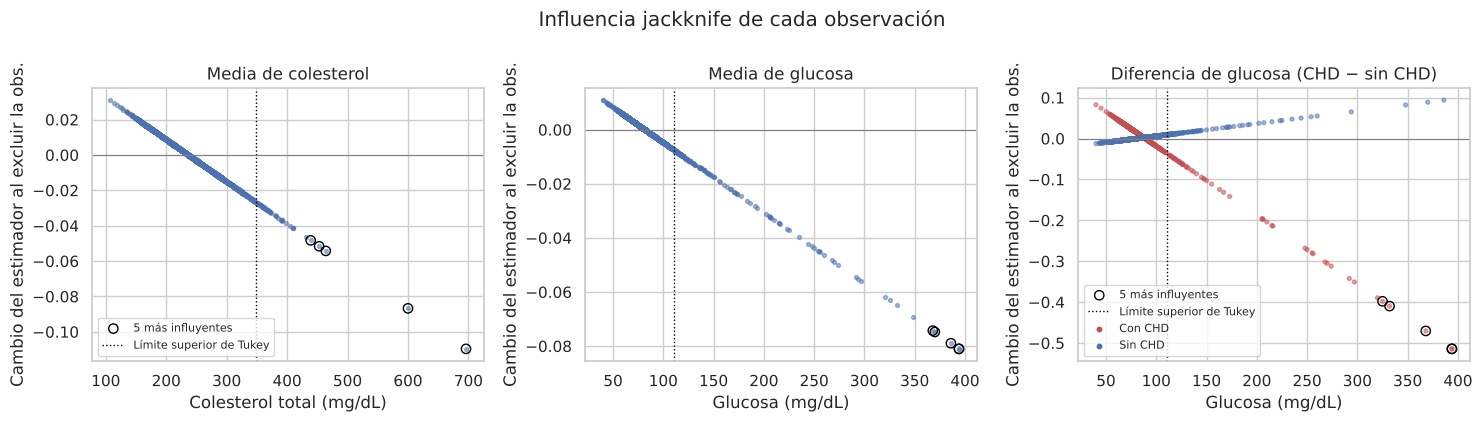

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
paneles = [("totChol", jk_media["totChol"], df["totChol"].dropna().to_numpy(float), "Media de colesterol"),
           ("glucose", jk_media["glucose"], df["glucose"].dropna().to_numpy(float), "Media de glucosa"),
           ("glucose", None, None, "Diferencia de glucosa (CHD − sin CHD)")]
for ax, (v, jm, x, titulo) in zip(axes, paneles):
    if jm is None:
        j = jk_dif["glucose"]
        x, cambio = j["valores"], j["loo"] - j["theta"]
        colores = np.where(j["grupo"] == 1, COLORES["riesgo"], COLORES["principal"])
    else:
        cambio = jm["loo"] - jm["estimacion"]
        colores = COLORES["principal"]
    inf, sup = limites_tukey(df[v])
    ax.scatter(x, cambio, s=8, alpha=.5, c=colores)
    top = np.argsort(-np.abs(cambio))[:5]
    ax.scatter(x[top], cambio[top], s=45, facecolors="none", edgecolors="black", label="5 más influyentes")
    ax.axvline(sup, color="black", ls=":", lw=1, label="Límite superior de Tukey")
    ax.axhline(0, color="0.5", lw=.8)
    ax.set(title=titulo, xlabel=NOMBRES[v], ylabel="Cambio del estimador al excluir la obs.")
axes[0].legend(fontsize=8, loc="lower left")
axes[2].scatter([], [], c=COLORES["riesgo"], s=10, label="Con CHD")
axes[2].scatter([], [], c=COLORES["principal"], s=10, label="Sin CHD")
axes[2].legend(fontsize=8, loc="lower left")
plt.suptitle("Influencia jackknife de cada observación", y=1.0)
guardar_figura("p5_fig1_influencia")

### Multicolinealidad (VIF)

La S1 encontró ρ = 0,78 entre presión sistólica y diastólica, y el bloque A confirmó que esa correlación es
la más estable. Interesa saber si ambas pueden analizarse juntas. Se calcula
el factor de inflación de varianza (VIF) de los predictores numéricos candidatos con los umbrales habituales
(< 5 sin problema; 5–10 moderado; > 10 severo).

In [7]:
PREDICTORES = ["age", "sysBP", "diaBP", "totChol", "BMI", "glucose", "cigsPerDay", "heartRate"]


def tabla_vif(columnas):
    X = sm.add_constant(df[columnas].dropna())
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=columnas)


vif = pd.DataFrame({
    "Todos": tabla_vif(PREDICTORES),
    "Sin diaBP": tabla_vif([c for c in PREDICTORES if c != "diaBP"]),
    "Sin sysBP": tabla_vif([c for c in PREDICTORES if c != "sysBP"]),
})
vif.index = [NOMBRES[c] for c in vif.index]
vif["Nivel (todos)"] = pd.cut(vif["Todos"], [0, 5, 10, np.inf], labels=["< 5", "5–10", "> 10"])
d_sys, d_dia = RESULTADOS_S1["diferencias"]["sysBP"]["g"], RESULTADOS_S1["diferencias"]["diaBP"]["g"]
print(f"Tamaño de efecto respecto de CHD en la S1: sistólica g = {d_sys} | diastólica g = {d_dia}")
guardar_tabla(vif.round(2), "p5_vif")

Tamaño de efecto respecto de CHD en la S1: sistólica g = 0.62 | diastólica g = 0.41


,Todos,Sin diaBP,Sin sysBP,Nivel (todos)
IMC (kg/m²),1.1900,1.1300,1.1900,< 5
Edad (años),1.3200,1.2800,1.1600,< 5
Cigarrillos por día,1.0500,1.0500,1.0500,< 5
Presión diastólica (mmHg),2.8500,NaN,1.2500,< 5
Glucosa (mg/dL),1.0400,1.0300,1.0300,< 5
Frecuencia cardíaca (lpm),1.0600,1.0600,1.0600,< 5
Presión sistólica (mmHg),3.1100,1.3600,NaN,< 5
Colesterol total (mg/dL),1.1000,1.1000,1.1000,< 5


**Interpretación 5.1.** El jackknife reproduce exactamente el error estándar clásico de las cuatro medias (por
ejemplo, 0,338 mmHg en presión sistólica y 0,386 mg/dL en glucosa) y su sesgo es nulo. Esto confirma que los
IC t de la S1 usan el error estándar correcto. Ninguna observación individual mueve las medias de forma
apreciable: el caso más influyente (colesterol de 696 mg/dL) cambia la media del colesterol en solo 0,11 mg/dL,
la sexta parte de su error estándar. Lo mismo ocurre con la glucosa de 394 mg/dL (0,08 mg/dL) y la presión
sistólica de 295 mmHg (0,04 mmHg). Las cinco observaciones más influyentes de cada media son atípicos de Tukey
de la cola superior.

La diferencia de glucosa es el estimador con mayor aceleración (a = 0,029, frente a 0,006 en la diferencia de
presión sistólica y ≤ 0,003 en las medias de edad, presión y colesterol). Por eso el IC BCa del bloque A es
asimétrico y se aleja del IC de Welch. Además, sus observaciones más influyentes son pacientes **con CHD** y
glucosa muy alta (394, 394, 368, 332 y 325 mg/dL), y cada uno, por sí solo, reduce la diferencia en 0,4 a
0,5 mg/dL al excluirlo. El efecto conjunto de esos pocos casos se cuantifica en 5.2.

**Multicolinealidad.** Todos los VIF están bajo 5, por lo que no hay multicolinealidad severa según los
umbrales habituales. Aun así, presión sistólica (3,11) y diastólica (2,85) son las únicas que se inflan
mutuamente: al quitar la diastólica, el VIF de la sistólica baja a 1,36. Se recomienda conservar
la **presión sistólica**, porque tiene el mayor tamaño de efecto respecto de CHD en la S1 (g = 0,62 frente a
0,41), su diferencia entre grupos es la más robusta de este análisis y su inclusión sola elimina la
redundancia.

## 5.2 Sensibilidad a outliers

Para cada variable se comparan cinco estimadores del centro: la media de la S1 (IC t), la media sin los
atípicos de Tukey (IC t), la media sin las 5 observaciones más influyentes del jackknife, la media recortada al
5 % (IC BCa) y la mediana (IC bootstrap: BCa, o percentil cuando BCa no es calculable). La media y la mediana estiman parámetros distintos cuando la distribución
es asimétrica, así que la mediana se informa como descriptor alternativo y no entra en el cálculo del
"cambio" de la media. Los atípicos se cuentan con el mismo criterio IQR de la S1.

In [8]:
filas_out, ic_out = [], {}
for s, v in enumerate(VARIABLES):
    x = df[v].dropna().to_numpy(float)
    atip = es_atipico(pd.Series(x)).to_numpy()
    inf_t, sup_t = limites_tukey(x)
    media = x.mean()
    top5 = np.argsort(-np.abs(jk_media[v]["estimacion"] - jk_media[v]["loo"]))[:5]
    sin_top5 = np.delete(x, top5)
    rec_ic = ic_bca(x, media_recortada, seed=SEED + 20 + s)
    med_ic = ic_bca(x, np.median, seed=SEED + 30 + s)
    ref = RESULTADOS_S1["ic"][CLAVE_S1[v]]["ic"] if v in CLAVE_S1 else ic_t(x)
    ic_out[v] = {
        "Media (S1, IC t)": (media, *ref),
        "Media sin atípicos (IC t)": (x[~atip].mean(), *ic_t(x[~atip])),
        "Media sin 5 más influyentes (IC t)": (sin_top5.mean(), *ic_t(sin_top5)),
        "Media recortada 5 % (IC BCa)": (media_recortada(x), *rec_ic),
        "Mediana (IC bootstrap)": (np.median(x), *med_ic),
    }
    filas_out.append({
        "Variable": NOMBRES[v], "n": len(x), "Método atípicos": "IQR (Tukey)",
        "Límite inf.": inf_t, "Límite sup.": sup_t, "n atípicos": int(atip.sum()),
        "% atípicos": 100 * atip.mean(), "Máximo": x.max(),
        "Media": media, "Media sin atípicos": x[~atip].mean(),
        "Δ % sin atípicos": cambio_pct(x[~atip].mean(), media),
        "Media sin 5 influyentes": sin_top5.mean(), "Δ % sin 5 influyentes": cambio_pct(sin_top5.mean(), media),
        "Media recortada 5 %": media_recortada(x), "Δ % recortada": cambio_pct(media_recortada(x), media),
        "Mediana": np.median(x), "Δ % mediana": cambio_pct(np.median(x), media),
    })
tabla_out = pd.DataFrame(filas_out).set_index("Variable")
guardar_tabla(tabla_out.round(3), "p5_outliers")

  BCa no calculable para median; se usa percentil


  BCa no calculable para median; se usa percentil


  BCa no calculable para median; se usa percentil


  BCa no calculable para median; se usa percentil


,n,Método atípicos,Límite inf.,Límite sup.,n atípicos,% atípicos,Máximo,Media,Media sin atípicos,Δ % sin atípicos,Media sin 5 influyentes,Δ % sin 5 influyentes,Media recortada 5 %,Δ % recortada,Mediana,Δ % mediana
Variable,,,,,,,,,,,,,,,,
Edad (años),4240,IQR (Tukey),21.0000,77.0000,0,0.0000,70.0000,49.5800,49.5800,0.0000,49.5570,-0.0470,49.4410,-0.2800,49.0000,-1.1700
Presión sistólica (mmHg),4240,IQR (Tukey),76.5000,184.5000,126,2.9720,295.0000,132.3550,130.3050,-1.5480,132.2120,-0.1080,130.9040,-1.0960,128.0000,-3.2900
Colesterol total (mg/dL),4190,IQR (Tukey),120.5000,348.5000,56,1.3370,696.0000,236.7000,234.8710,-0.7720,236.3490,-0.1480,235.1700,-0.6460,234.0000,-1.1400
Glucosa (mg/dL),3852,IQR (Tukey),47.0000,111.0000,188,4.8810,394.0000,81.9640,78.4890,-4.2400,81.5730,-0.4760,79.4390,-3.0810,78.0000,-4.8360


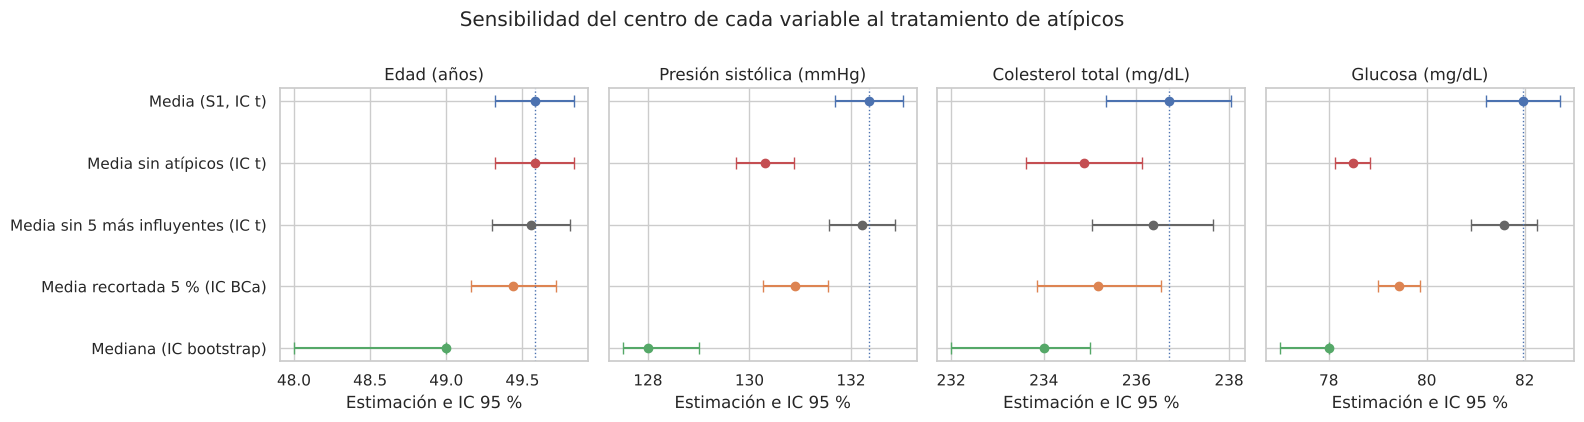

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
etiquetas = list(next(iter(ic_out.values())).keys())
colores_est = [COLORES["clasico"], COLORES["riesgo"], "0.4", COLORES["percentil"], COLORES["bca"]]
for ax, v in zip(axes, VARIABLES):
    for k, (et, col) in enumerate(zip(etiquetas, colores_est)):
        est, lo, hi = ic_out[v][et]
        ax.errorbar(est, k, xerr=[[est - lo], [hi - est]], fmt="o", color=col, capsize=4, ms=6)
    ax.axvline(ic_out[v]["Media (S1, IC t)"][0], color=COLORES["clasico"], ls=":", lw=1)
    ax.set(title=NOMBRES[v], xlabel="Estimación e IC 95 %")
axes[0].set_yticks(range(len(etiquetas)), etiquetas)
axes[0].invert_yaxis()
plt.suptitle("Sensibilidad del centro de cada variable al tratamiento de atípicos", y=1.0)
guardar_figura("p5_fig2_outliers")

**Las diferencias de la Tabla 4 sin atípicos.** Se repite la prueba de Welch de la S1 (presión sistólica) y la
diferencia de glucosa con cuatro alternativas: sin atípicos de Tukey, sin las 5 observaciones más influyentes
del jackknife de la diferencia, con medias recortadas al 5 % (prueba de Yuen, `ttest_ind(trim=0.05)`) y con
medianas (prueba de la mediana de Mood).

In [10]:
def alternativas_diferencia(v):
    # Diferencia CHD - sin CHD bajo cada tratamiento de atípicos, con su p
    x1, x0 = grupos(v)
    base = welch(x1, x0)
    inf, sup = limites_tukey(df[v])
    filas = [{"Tratamiento": "S1: Welch con todos los datos", **base}]
    a1, a0 = x1[(x1 >= inf) & (x1 <= sup)], x0[(x0 >= inf) & (x0 <= sup)]
    filas.append({"Tratamiento": "Welch sin atípicos de Tukey", **welch(a1, a0)})
    j = jk_dif[v]
    top5 = np.argsort(-np.abs(j["theta"] - j["loo"]))[:5]
    quitar = np.zeros(len(j["loo"]), bool)
    quitar[top5] = True
    filas.append({"Tratamiento": "Welch sin 5 más influyentes",
                  **welch(x1[~quitar[:len(x1)]], x0[~quitar[len(x1):]])})
    yuen = stats.ttest_ind(x1, x0, equal_var=False, trim=0.05)
    filas.append({"Tratamiento": "Yuen (medias recortadas 5 %)",
                  "dif": media_recortada(x1) - media_recortada(x0), "t": yuen.statistic, "p": yuen.pvalue,
                  "n1": len(x1), "n0": len(x0)})
    mood = stats.median_test(x1, x0)
    filas.append({"Tratamiento": "Mood (medianas)", "dif": np.median(x1) - np.median(x0), "p": mood.pvalue,
                  "n1": len(x1), "n0": len(x0)})
    t = pd.DataFrame(filas)
    t.insert(0, "Variable", NOMBRES[v])
    t["Δ % vs S1"] = cambio_pct(t["dif"], base["dif"])
    t["Decisión"] = np.where(t["p"] < ALPHA, "Se rechaza H₀", "No se rechaza H₀")
    return t


tabla_dif = pd.concat([alternativas_diferencia("sysBP"), alternativas_diferencia("glucose")])
tabla_dif = tabla_dif.set_index(["Variable", "Tratamiento"])
guardar_tabla(tabla_dif, "p5_diferencias_sin_atipicos")

dif  ic_inf  \
Variable                 Tratamiento                                     
Presión sistólica (mmHg) S1: Welch con todos los datos 13.2815 11.1111   
                         Welch sin atípicos de Tukey    9.6643  7.9187   
                         Welch sin 5 más influyentes   12.4663 10.4099   
                         Yuen (medias recortadas 5 %)  13.1465     NaN   
                         Mood (medianas)               12.0000     NaN   
Glucosa (mg/dL)          S1: Welch con todos los datos  8.3292  4.9508   
                         Welch sin atípicos de Tukey    0.8328 -0.2054   
                         Welch sin 5 más influyentes    6.0067  3.2958   
                         Yuen (medias recortadas 5 %)   3.3376     NaN   
                         Mood (medianas)                1.0000     NaN   

                                                        ic_sup       t      p  \
Variable                 Tratamiento                                            
Presión sistólica (mmHg) S1: Welch con todos los datos 15.4519 12.0123 0.0000   
                         Welch sin atípicos de Tukey   11.4099 10.8683 0.0000   
                         Welch sin 5 más influyentes   14.5227 11.8998 0.0000   
                         Yuen (medias recortadas 5 %)      NaN 12.0139 0.0000   
                         Mood (medianas)                   NaN     NaN 0.0000   
Glucosa (mg/dL)          S1: Welch con todos los datos 11.7075  4.8414 0.0000   
                         Welch sin atípicos de Tukey    1.8709  1.5748 0.1157   
                         Welch sin 5 más influyentes    8.7175  4.3508 0.0000   
                         Yuen (medias recortadas 5 %)      NaN  3.7771 0.0002   
                         Mood (medianas)                   NaN     NaN 0.0708   

                                                            d   n1    n0  \
Variable                 Tratamiento                                       
Presión sistólica (mmHg) S1: Welch con todos los datos 0.6173  644  3596   
                         Welch sin atípicos de Tukey   0.5238  594  3520   
                         Welch sin 5 más influyentes   0.5879  639  3596   
                         Yuen (medias recortadas 5 %)     NaN  644  3596   
                         Mood (medianas)                  NaN  644  3596   
Glucosa (mg/dL)          S1: Welch con todos los datos 0.3504  594  3258   
                         Welch sin atípicos de Tukey   0.0756  537  3127   
                         Welch sin 5 más influyentes   0.2781  589  3258   
                         Yuen (medias recortadas 5 %)     NaN  594  3258   
                         Mood (medianas)                  NaN  594  3258   

                                                        Δ % vs S1  \
Variable                 Tratamiento                                
Presión sistólica (mmHg) S1: Welch con todos los datos     0.0000   
                         Welch sin atípicos de Tukey     -27.2349   
                         Welch sin 5 más influyentes      -6.1378   
                         Yuen (medias recortadas 5 %)     -1.0159   
                         Mood (medianas)                  -9.6486   
Glucosa (mg/dL)          S1: Welch con todos los datos     0.0000   
                         Welch sin atípicos de Tukey     -90.0018   
                         Welch sin 5 más influyentes     -27.8841   
                         Yuen (medias recortadas 5 %)    -59.9283   
                         Mood (medianas)                 -87.9940   

                                                                Decisión  
Variable                 Tratamiento                                      
Presión sistólica (mmHg) S1: Welch con todos los datos     Se rechaza H₀  
                         Welch sin atípicos de Tukey       Se rechaza H₀  
                         Welch sin 5 más influyentes       Se rechaza H₀  
                         Yuen (medias recortadas 5 %)      Se rechaza H₀  
     

**Interpretación 5.2.** Las medias de **edad, presión sistólica y colesterol** son robustas: con cualquier
tratamiento de atípicos cambian como máximo un 1,6 %, es decir, 1 a 2 unidades, sin relevancia práctica. La edad
no tiene atípicos y sus cinco valores más influyentes cambian la media en 0,005 años. Como con n ≈ 4.200 los IC
son muy estrechos, en presión sistólica la media sin atípicos y la media recortada quedan fuera del IC de la S1.
Esto refleja que la media incluye la cola superior de una variable asimétrica, no un problema del estimador.
La **glucosa** muestra el mismo patrón con más intensidad: −4,2 % sin atípicos, −3,1 % con la media recortada, y
mediana de 78 mg/dL frente a una media de 82. Con la regla del 10 % su media se clasifica como robusta, pero el
"centro" de la glucosa depende claramente de cómo se traten sus 188 atípicos (4,9 %, todos por encima de
111 mg/dL), y eso pesa mucho más en la comparación entre grupos.

La **diferencia de presión sistólica** sigue siendo significativa (p < 0,001) con los cinco tratamientos y su
magnitud va de 9,7 a 13,3 mmHg. Al excluir los 126 atípicos de Tukey (> 184,5 mmHg), la diferencia baja un 27 % y
la d de Cohen pasa de 0,62 a 0,52. No es un artefacto: esos valores son presiones de hipertensión severa,
clínicamente plausibles y concentradas en el grupo con CHD, y quitarlos elimina parte de la señal real. La
existencia y la dirección del efecto son robustas; su magnitud depende de la cola superior.

La **diferencia de glucosa** no es robusta. Sin los atípicos de Tukey cae de 8,33 a 0,83 mg/dL
(IC [−0,21; 1,87], p = 0,116), y la diferencia de medianas es de solo 1 mg/dL (prueba de Mood, p = 0,071).
Con medias recortadas al 5 % se mantiene significativa (3,34 mg/dL, p < 0,001), pero es un 60 % menor. La
diferencia que reportó la S1 es real en promedio, pero se concentra en una minoría de pacientes con glucosa
alta (rango diabético). Para el paciente típico, la glucosa no difiere entre quienes desarrollan CHD y
quienes no.

## 5.3 Sensibilidad a supuestos y a la limpieza

### a) Pearson vs Spearman, con y sin atípicos

La S1 eligió Spearman porque varias variables son asimétricas. Si Pearson y Spearman coinciden y ninguno
cambia al quitar atípicos, la correlación no depende del supuesto de linealidad/normalidad ni de valores
extremos. Se agrega el par colesterol–glucosa, que el bloque A clasificó como inestable.

In [11]:
PARES = list(RESULTADOS_S1["correlaciones"]) + [("totChol", "glucose")]
filas_corr = []
for x_n, y_n in PARES:
    d = df[[x_n, y_n]].dropna()
    sin = d[~(es_atipico(d[x_n]) | es_atipico(d[y_n]))]
    fila = {"Par": f"{NOMBRES[x_n]} – {NOMBRES[y_n]}",
            "ρ S1": RESULTADOS_S1["correlaciones"].get((x_n, y_n), np.nan), "n": len(d), "n sin atípicos": len(sin)}
    for etiqueta, datos in [("todos", d), ("sin atípicos", sin)]:
        fila[f"Spearman {etiqueta}"] = stats.spearmanr(datos[x_n], datos[y_n]).statistic
        fila[f"Pearson {etiqueta}"] = stats.pearsonr(datos[x_n], datos[y_n]).statistic
    filas_corr.append(fila)
tabla_corr = pd.DataFrame(filas_corr).set_index("Par")
tabla_corr["Pearson − Spearman"] = tabla_corr["Pearson todos"] - tabla_corr["Spearman todos"]
tabla_corr["Δ Spearman sin atípicos"] = tabla_corr["Spearman sin atípicos"] - tabla_corr["Spearman todos"]
tabla_corr["Δ Pearson sin atípicos"] = tabla_corr["Pearson sin atípicos"] - tabla_corr["Pearson todos"]
guardar_tabla(tabla_corr.round(4), "p5_pearson_spearman")

,ρ S1,n,n sin atípicos,Spearman todos,Pearson todos,Spearman sin atípicos,Pearson sin atípicos,Pearson − Spearman,Δ Spearman sin atípicos,Δ Pearson sin atípicos
Par,,,,,,,,,,
Presión sistólica (mmHg) – Presión diastólica (mmHg),0.7800,4240,4082,0.7776,0.7840,0.7592,0.7546,0.0063,-0.0184,-0.0294
Edad (años) – Presión sistólica (mmHg),0.3900,4240,4114,0.3910,0.3941,0.3649,0.3653,0.0031,-0.0261,-0.0287
IMC (kg/m²) – Presión diastólica (mmHg),0.3700,4221,4049,0.3747,0.3774,0.3465,0.3321,0.0026,-0.0282,-0.0453
Colesterol total (mg/dL) – Glucosa (mg/dL),NaN,3842,3611,0.0299,0.0465,0.0174,0.0240,0.0166,-0.0125,-0.0226


### b) Imputación de la glucosa

La S1 usó casos disponibles para la glucosa (388 faltantes, 9,2 %). Se compara con dos imputaciones simples:
la mediana global y la
mediana según el diagnóstico de diabetes, ya que los diabéticos tienen glucosas mucho más altas.

In [12]:
glu = df["glucose"]
med_diab = df.groupby("diabetes")["glucose"].median()
versiones_glu = {
    "Casos disponibles (S1)": glu,
    "Imputación por mediana global": glu.fillna(glu.median()),
    "Imputación por mediana según diabetes": glu.fillna(df["diabetes"].map(med_diab)),
}
print("Mediana de glucosa según diabetes:", med_diab.to_dict(),
      "| faltantes en diabéticos:", int(glu.isna()[df["diabetes"] == 1].sum()))
filas_imp = []
for nombre, serie in versiones_glu.items():
    x = serie.dropna().to_numpy(float)
    lo, hi = ic_t(x)
    w = welch(*grupos("glucose", df.assign(glucose=serie)))
    filas_imp.append({"Versión": nombre, "n": len(x), "Media": x.mean(), "DE": x.std(ddof=1),
                      "Amplitud IC 95 % media": hi - lo, "Dif. CHD − sin CHD": w["dif"],
                      "IC dif. inf.": w["ic_inf"], "IC dif. sup.": w["ic_sup"], "p Welch": w["p"]})
tabla_imp = pd.DataFrame(filas_imp).set_index("Versión")
tabla_imp["Δ % dif. vs S1"] = cambio_pct(tabla_imp["Dif. CHD − sin CHD"], tabla_imp["Dif. CHD − sin CHD"].iloc[0])
guardar_tabla(tabla_imp.round(4), "p5_imputacion_glucosa")

Mediana de glucosa según diabetes: {0: 78.0, 1: 145.0} | faltantes en diabéticos: 4


,n,Media,DE,Amplitud IC 95 % media,Dif. CHD − sin CHD,IC dif. inf.,IC dif. sup.,p Welch,Δ % dif. vs S1
Versión,,,,,,,,,
Casos disponibles (S1),3852,81.9637,23.9543,1.5134,8.3292,4.9508,11.7075,0.0000,0.0000
Imputación por mediana global,4240,81.6009,22.8603,1.3766,7.7263,4.6045,10.8481,0.0000,-7.2379
Imputación por mediana según diabetes,4240,81.6642,22.9428,1.3815,7.8971,4.7656,11.0286,0.0000,-5.1872


### c) Imputación de cigarrillos por día

La S1 imputó los 29 faltantes de `cigsPerDay` (todos fumadores) con la mediana de los fumadores (20). Se
compara con excluir esos casos (datos originales, `cargar_datos(limpio=False)`).

In [13]:
raw = cargar_datos(limpio=False)
filas_cig = []
for nombre, datos in [("Imputación con mediana 20 (S1)", df), ("Excluir los 29 casos", raw.dropna(subset=["cigsPerDay"]))]:
    fum = datos.loc[datos["currentSmoker"] == 1, "cigsPerDay"]
    w = welch(*grupos("cigsPerDay", datos))
    filas_cig.append({"Versión": nombre, "n": len(datos), "Media fumadores": fum.mean(),
                      "DE fumadores": fum.std(), "Dif. CHD − sin CHD": w["dif"], "IC inf.": w["ic_inf"],
                      "IC sup.": w["ic_sup"], "p Welch": w["p"],
                      "Spearman con CHD": stats.spearmanr(datos["cigsPerDay"], datos["TenYearCHD"]).statistic})
tabla_cig = pd.DataFrame(filas_cig).set_index("Versión")
tabla_cig["Δ % dif. vs S1"] = cambio_pct(tabla_cig["Dif. CHD − sin CHD"], tabla_cig["Dif. CHD − sin CHD"].iloc[0])
assert round(tabla_cig["Dif. CHD − sin CHD"].iloc[0], 2) == RESULTADOS_S1["diferencias"]["cigsPerDay"]["dif"]
guardar_tabla(tabla_cig.round(4), "p5_imputacion_cigs")

,n,Media fumadores,DE fumadores,Dif. CHD − sin CHD,IC inf.,IC sup.,p Welch,Spearman con CHD,Δ % dif. vs S1
Versión,,,,,,,,,
Imputación con mediana 20 (S1),4240,18.3790,10.7925,1.8597,0.7841,2.9353,0.0007,0.0416,0.0000
Excluir los 29 casos,4211,18.3562,10.8663,1.9154,0.8370,2.9937,0.0005,0.0435,2.9917


### d) Perturbación con ruido de medición

Con el método de perturbación, X_sint = X + ε con ε ~ N(0, (δ·s)²), se
agrega ruido proporcional a la desviación estándar de cada variable (δ = 5 % y 10 %) y se recalculan la
diferencia de presión sistólica y las correlaciones de Spearman en B = 10.000 réplicas. Simula errores de
medición, por ejemplo en la toma de presión. Si las conclusiones dependieran de valores exactos o de pocos
casos, el ruido las cambiaría.

In [14]:
DELTAS = [0.05, 0.10]


def spearman_filas(X, Y):
    # Spearman fila a fila (X, Y de forma réplicas × n)
    rx = stats.rankdata(X, axis=1)
    ry = stats.rankdata(Y, axis=1)
    rx -= rx.mean(axis=1, keepdims=True)
    ry -= ry.mean(axis=1, keepdims=True)
    return np.sum(rx * ry, axis=1) / np.sqrt(np.sum(rx**2, axis=1) * np.sum(ry**2, axis=1))


pas = df["sysBP"].to_numpy(float)
perturbacion = {}
for delta in DELTAS:
    rng_p = np.random.default_rng(SEED + int(delta * 100))
    difs = np.empty(B)
    for i0 in range(0, B, 1_000):
        ruido = rng_p.normal(0, delta * pas.std(ddof=1), size=(1_000, len(pas)))
        P = pas + ruido
        difs[i0:i0 + 1_000] = P[:, chd == 1].mean(axis=1) - P[:, chd == 0].mean(axis=1)
    perturbacion[("Diferencia PAS (CHD − sin CHD)", delta)] = difs
    for x_n, y_n in PARES[:3]:
        d = df[[x_n, y_n]].dropna()
        x, y = d[x_n].to_numpy(float), d[y_n].to_numpy(float)
        rhos = np.empty(B)
        for i0 in range(0, B, 500):
            X = x + rng_p.normal(0, delta * x.std(ddof=1), size=(500, len(x)))
            Y = y + rng_p.normal(0, delta * y.std(ddof=1), size=(500, len(y)))
            rhos[i0:i0 + 500] = spearman_filas(X, Y)
        perturbacion[(f"ρ {NOMBRES[x_n]} – {NOMBRES[y_n]}", delta)] = rhos

base_pert = {"Diferencia PAS (CHD − sin CHD)": pas[chd == 1].mean() - pas[chd == 0].mean()}
for x_n, y_n in PARES[:3]:
    d = df[[x_n, y_n]].dropna()
    base_pert[f"ρ {NOMBRES[x_n]} – {NOMBRES[y_n]}"] = stats.spearmanr(d[x_n], d[y_n]).statistic
tabla_pert = pd.DataFrame([
    {"Resultado": r, "δ": delta, "Valor original": base_pert[r], "Media perturbada": v.mean(),
     "DE perturbada": v.std(ddof=1), "P2,5": np.quantile(v, .025), "P97,5": np.quantile(v, .975),
     "Δ % media vs original": cambio_pct(v.mean(), base_pert[r]),
     "Δ % máx. (P2,5 o P97,5)": max(abs(cambio_pct(np.quantile(v, q), base_pert[r])) for q in (.025, .975))}
    for (r, delta), v in perturbacion.items()
]).set_index(["Resultado", "δ"])
guardar_tabla(tabla_pert.round(4), "p5_perturbacion")

,,Valor original,Media perturbada,DE perturbada,"P2,5","P97,5",Δ % media vs original,"Δ % máx. (P2,5 o P97,5)"
Resultado,δ,,,,,,,
Diferencia PAS (CHD − sin CHD),0.0500,13.2815,13.2812,0.0476,13.1876,13.3740,-0.0022,0.7070
ρ Presión sistólica (mmHg) – Presión diastólica (mmHg),0.0500,0.7776,0.7749,0.0009,0.7732,0.7766,-0.3519,0.5728
ρ Edad (años) – Presión sistólica (mmHg),0.0500,0.3910,0.3898,0.0011,0.3875,0.3920,-0.3102,0.8899
ρ IMC (kg/m²) – Presión diastólica (mmHg),0.0500,0.3747,0.3737,0.0012,0.3714,0.3761,-0.2762,0.9070
Diferencia PAS (CHD − sin CHD),0.1000,13.2815,13.2804,0.0942,13.0976,13.4668,-0.0081,1.3957
ρ Presión sistólica (mmHg) – Presión diastólica (mmHg),0.1000,0.7776,0.7669,0.0017,0.7635,0.7703,-1.3724,1.8095
ρ Edad (años) – Presión sistólica (mmHg),0.1000,0.3910,0.3865,0.0023,0.3820,0.3909,-1.1434,2.2923
ρ IMC (kg/m²) – Presión diastólica (mmHg),0.1000,0.3747,0.3703,0.0023,0.3657,0.3749,-1.1824,2.4118


### e) Distribuciones alternativas: sesgo, ECM y cobertura (datos sintéticos)

La glucosa es la variable que más se aleja de la normalidad (asimetría ≈ 6, curtosis ≈ 59). Para saber si el IC t
de la S1 es confiable para ella y qué estimador conviene usar, se generan datos sintéticos desde cuatro
distribuciones ajustadas a la glucosa observada (generación paramétrica y remuestreo de los datos):

| Distribución | Generación |
| --- | --- |
| Normal | N(media, DE) de la glucosa observada |
| Lognormal | exp(N(μ, σ)) con μ y σ del log de la glucosa |
| Empírica | remuestreo con reemplazo de las 3.852 glucosas observadas (incluye sus atípicos) |
| Lognormal contaminada | lognormal con 5 % de valores extremos uniformes entre el límite de Tukey y el máximo (394) |

Para cada distribución y n ∈ {50, 200, 3.852} se simulan B = 10.000 muestras y se calculan la media, la media
recortada al 5 % y la mediana. Cada estimador se compara con *su propio* parámetro poblacional (sesgo, DE y
ECM) y se registra la **cobertura del IC t al 95 %** para la media, que
es el supuesto que usó la S1.

In [15]:
glu_obs = df["glucose"].dropna().to_numpy(float)
mu_log, sd_log = np.log(glu_obs).mean(), np.log(glu_obs).std(ddof=1)
lim_sup_glu = limites_tukey(glu_obs)[1]


def generar(nombre, size, rng_g):
    if nombre == "Normal":
        return rng_g.normal(glu_obs.mean(), glu_obs.std(ddof=1), size)
    if nombre == "Lognormal":
        return np.exp(rng_g.normal(mu_log, sd_log, size))
    if nombre == "Empírica":
        return rng_g.choice(glu_obs, size=size, replace=True)
    x = np.exp(rng_g.normal(mu_log, sd_log, size))
    contaminar = rng_g.random(size) < 0.05
    x[contaminar] = rng_g.uniform(lim_sup_glu, glu_obs.max(), contaminar.sum())
    return x


DISTRIBUCIONES = ["Normal", "Lognormal", "Empírica", "Lognormal contaminada"]
ESTIMADORES = {"Media": lambda X: X.mean(axis=1), "Media recortada 5 %": lambda X: media_recortada(X, axis=1),
               "Mediana": lambda X: np.median(X, axis=1)}
TAMANOS = [50, 200, len(glu_obs)]

# Parámetros poblacionales: exactos para la empírica; con 2.000.000 de draws para las demás
rng_pob = np.random.default_rng(SEED + 99)
poblacion = {}
for dist in DISTRIBUCIONES:
    p = glu_obs if dist == "Empírica" else generar(dist, 2_000_000, rng_pob)
    poblacion[dist] = {"Media": p.mean(), "Media recortada 5 %": media_recortada(p), "Mediana": np.median(p)}

filas_sim = []
for d_i, dist in enumerate(DISTRIBUCIONES):
    for n in TAMANOS:
        rng_s = np.random.default_rng(SEED + 1_000 * (d_i + 1) + n)
        est = {e: np.empty(B) for e in ESTIMADORES}
        cubre = np.empty(B, bool)
        lote = max(1, min(B, 2_000_000 // n))
        for i0 in range(0, B, lote):
            m = min(lote, B - i0)
            X = generar(dist, (m, n), rng_s)
            for e, f in ESTIMADORES.items():
                est[e][i0:i0 + m] = f(X)
            medias, ee = X.mean(axis=1), X.std(axis=1, ddof=1) / np.sqrt(n)
            t_c = stats.t.ppf(1 - ALPHA / 2, n - 1)
            cubre[i0:i0 + m] = np.abs(medias - poblacion[dist]["Media"]) <= t_c * ee
        for e in ESTIMADORES:
            theta = poblacion[dist][e]
            sesgo = est[e].mean() - theta
            filas_sim.append({"Distribución": dist, "n": n, "Estimador": e, "Parámetro": theta,
                              "Sesgo": sesgo, "Sesgo relativo %": 100 * sesgo / theta,
                              "DE": est[e].std(ddof=1), "ECM": np.mean((est[e] - theta) ** 2),
                              "Cobertura IC t 95 %": 100 * cubre.mean() if e == "Media" else np.nan})
tabla_sim = pd.DataFrame(filas_sim).set_index(["Distribución", "n", "Estimador"])
tabla_sim["Eficiencia relativa vs media"] = (
    tabla_sim["DE"].xs("Media", level="Estimador").reindex(tabla_sim.index.droplevel("Estimador")).to_numpy()
    / tabla_sim["DE"]) ** 2
guardar_tabla(tabla_sim.round(4), "p5_sinteticos")

Parámetro   Sesgo  \
Distribución          n    Estimador                                
Normal                50   Media                  81.9381  0.0267   
                           Media recortada 5 %    81.9435  0.0198   
                           Mediana                81.9205  0.0522   
                      200  Media                  81.9381  0.0151   
                           Media recortada 5 %    81.9435  0.0063   
                           Mediana                81.9205  0.0186   
                      3852 Media                  81.9381  0.0272   
                           Media recortada 5 %    81.9435  0.0220   
                           Mediana                81.9205  0.0428   
Lognormal             50   Media                  81.5998  0.0103   
                           Media recortada 5 %    80.9554  0.1505   
                           Mediana                79.9056  0.0588   
                      200  Media                  81.5998  0.0212   
                           Media recortada 5 %    80.9554  0.0353   
                           Mediana                79.9056  0.0371   
                      3852 Media                  81.5998  0.0084   
                           Media recortada 5 %    80.9554  0.0101   
                           Mediana                79.9056  0.0111   
Empírica              50   Media                  81.9637  0.0152   
                           Media recortada 5 %    79.4386  0.3424   
                           Mediana                78.0000  0.1251   
                      200  Media                  81.9637  0.0074   
                           Media recortada 5 %    79.4386  0.0383   
                           Mediana                78.0000 -0.0306   
                      3852 Media                  81.9637  0.0059   
                           Media recortada 5 %    79.4386  0.0096   
                           Mediana                78.0000 -0.0254   
Lognormal contaminada 50   Media                  90.1091  0.1433   
                           Media recortada 5 %    83.0801  1.6702   
                           Mediana                80.9895  0.1340   
                      200  Media                  90.1091  0.0986   
                           Media recortada 5 %    83.0801  0.2940   
                           Mediana                80.9895  0.0610   
                      3852 Media                  90.1091  0.0448   
                           Media recortada 5 %    83.0801  0.0427   
                           Mediana                80.9895  0.0133   

                                                Sesgo relativo %     DE  \
Distribución          n    Estimador                                      
Normal                50   Media                          0.0326 3.3945   
                           Media recortada 5 %            0.0242 3.4246   
                           Mediana                        0.0638 4.1673   
                      200  Media                          0.0185 1.6866   
                           Media recortada 5 %            0.0077 1.7096   
                           Mediana                        0.0228 2.1026   
                      3852 Media                          0.0332 0.3891   
                           Media recortada 5 %            0.0268 0.3958   
                           Mediana                        0.0523 0.4884   
Lognormal             50   Media                          0.0126 2.4018   
                           Media recortada 5 %            0.1859 2.4018   
                           Mediana                        0.0735 2.8952   
                      200  Media                          0.0260 1.1871   
                           Media recortada 5 %            0.0436 1.1868   
                           Mediana                        0.0465 1.4383   
                      3852 Media                          0.0103 0.2723   
                           Media recortada 5 %            0.0125 0.2721   


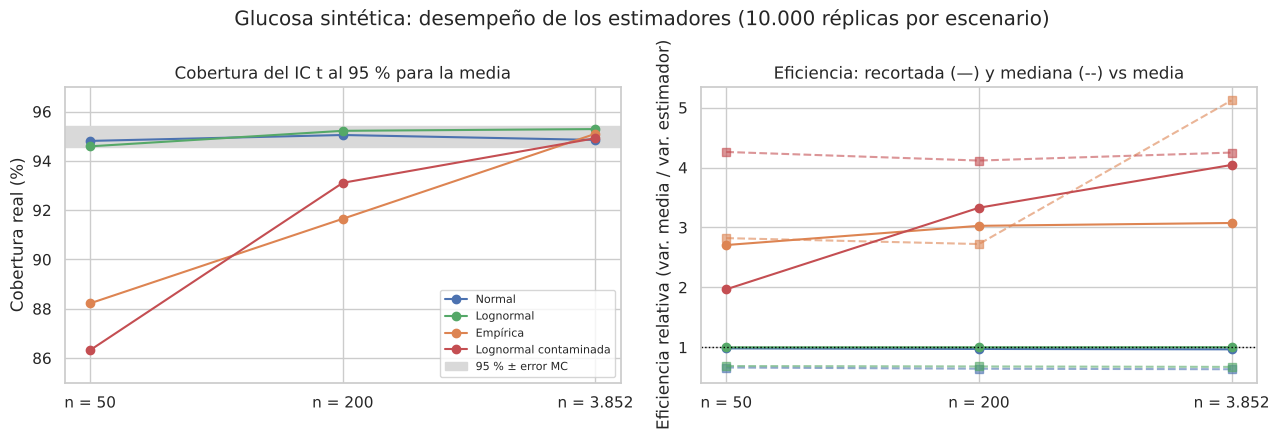

In [16]:
cob = tabla_sim.xs("Media", level="Estimador")["Cobertura IC t 95 %"].unstack("Distribución")[DISTRIBUCIONES]
efi = tabla_sim["Eficiencia relativa vs media"].unstack("Estimador")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
paleta = [COLORES["principal"], COLORES["mediana"], COLORES["percentil"], COLORES["riesgo"]]
for dist, col in zip(DISTRIBUCIONES, paleta):
    axes[0].plot(range(len(TAMANOS)), cob[dist], marker="o", color=col, label=dist)
    axes[1].plot(range(len(TAMANOS)), efi.loc[dist, "Media recortada 5 %"], marker="o", color=col, label=dist)
    axes[1].plot(range(len(TAMANOS)), efi.loc[dist, "Mediana"], marker="s", ls="--", color=col, alpha=.6)
# Banda de error Monte Carlo de una cobertura de 95 % con B réplicas
banda = 1.96 * np.sqrt(.95 * .05 / B) * 100
axes[0].axhspan(95 - banda, 95 + banda, color="0.85", label="95 % ± error MC")
axes[0].set(ylabel="Cobertura real (%)", title="Cobertura del IC t al 95 % para la media", ylim=(85, 97))
axes[1].axhline(1, color="black", lw=1, ls=":")
axes[1].set(ylabel="Eficiencia relativa (var. media / var. estimador)",
            title="Eficiencia: recortada (—) y mediana (--) vs media")
for ax in axes:
    ax.set_xticks(range(len(TAMANOS)), [f"n = {n:,}".replace(",", ".") for n in TAMANOS])
axes[0].legend(fontsize=8, loc="lower right")
plt.suptitle(f"Glucosa sintética: desempeño de los estimadores ({B:,} réplicas por escenario)".replace(",", "."), y=1.0)
guardar_figura("p5_fig4_sinteticos")

### f) Análisis OAT y diagrama de tornado

Cada decisión metodológica se cambia *una a la vez*
(one-at-a-time) y se registra el nuevo valor de la diferencia de la S1. La perturbación con ruido se
representa con su rango P2,5–P97,5. Las barras se ordenan de mayor a menor impacto.

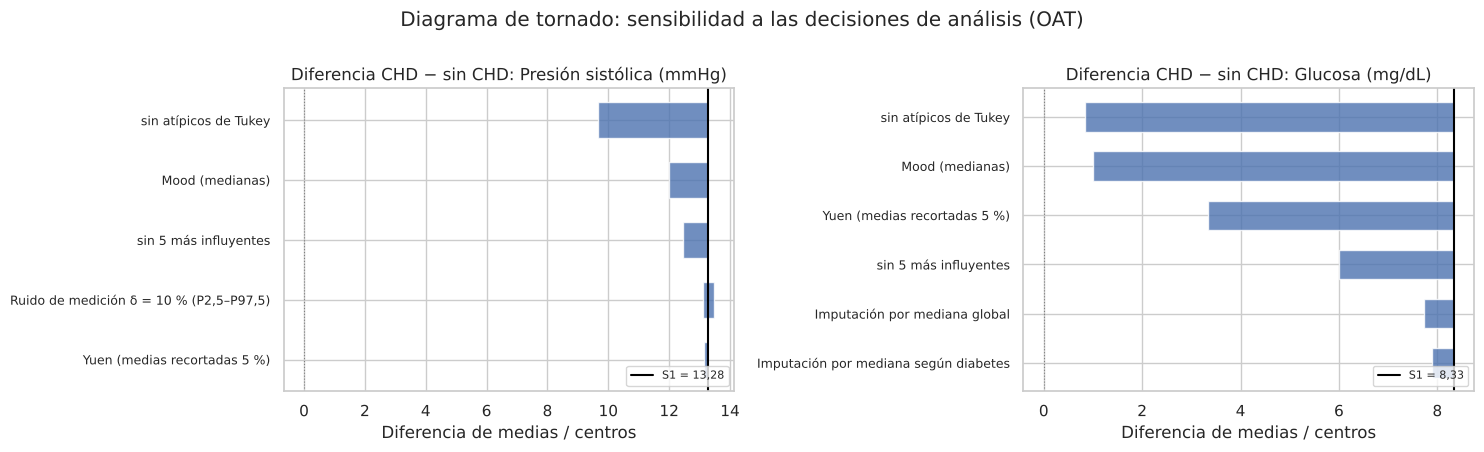

bajo  \
Resultado                              Decisión                                          
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            13.1465   
                                       Ruido de medición δ = 10 % (P2,5–P97,5) 13.0976   
                                       sin 5 más influyentes                   12.4663   
                                       Mood (medianas)                         12.0000   
                                       sin atípicos de Tukey                    9.6643   
Diferencia de Glucosa (mg/dL)          Imputación por mediana según diabetes    7.8971   
                                       Imputación por mediana global            7.7263   
                                       sin 5 más influyentes                    6.0067   
                                       Yuen (medias recortadas 5 %)             3.3376   
                                       Mood (medianas)                          1.0000   
                                       sin atípicos de Tukey                    0.8328   

                                                                                  alto  \
Resultado                              Decisión                                          
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            13.2815   
                                       Ruido de medición δ = 10 % (P2,5–P97,5) 13.4668   
                                       sin 5 más influyentes                   13.2815   
                                       Mood (medianas)                         13.2815   
                                       sin atípicos de Tukey                   13.2815   
Diferencia de Glucosa (mg/dL)          Imputación por mediana según diabetes    8.3292   
                                       Imputación por mediana global            8.3292   
                                       sin 5 más influyentes                    8.3292   
                                       Yuen (medias recortadas 5 %)             8.3292   
                                       Mood (medianas)                          8.3292   
                                       sin atípicos de Tukey                    8.3292   

                                                                                 valor  \
Resultado                              Decisión                                          
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            13.1465   
                                       Ruido de medición δ = 10 % (P2,5–P97,5)     NaN   
                                       sin 5 más influyentes                   12.4663   
                                       Mood (medianas)                         12.0000   
                                       sin atípicos de Tukey                    9.6643   
Diferencia de Glucosa (mg/dL)          Imputación por mediana según diabetes    7.8971   
                                       Imputación por mediana global            7.7263   
                                       sin 5 más influyentes                    6.0067   
                                       Yuen (medias recortadas 5 %)             3.3376   
                                       Mood (medianas)                          1.0000   
                                       sin atípicos de Tukey                    0.8328   

                                                                                    p  \
Resultado                              Decisión                                         
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            0.0000   
                                       Ruido de medición δ = 10 % (P2,5–P97,5)    NaN   
                                       sin 5 más influyentes                   0.0000   
                                       Mood (medianas)                         0.0000   
                                   

In [17]:
def filas_tornado(v):
    base = tabla_dif.loc[(NOMBRES[v], "S1: Welch con todos los datos"), "dif"]
    filas = []
    for trat in tabla_dif.loc[NOMBRES[v]].index[1:]:
        val = tabla_dif.loc[(NOMBRES[v], trat), "dif"]
        filas.append({"Decisión": trat.replace("Welch ", ""), "bajo": min(base, val), "alto": max(base, val),
                      "valor": val, "p": tabla_dif.loc[(NOMBRES[v], trat), "p"]})
    if v == "sysBP":
        r = perturbacion[("Diferencia PAS (CHD − sin CHD)", 0.10)]
        filas.append({"Decisión": "Ruido de medición δ = 10 % (P2,5–P97,5)", "bajo": np.quantile(r, .025),
                      "alto": np.quantile(r, .975), "valor": np.nan, "p": np.nan})
    else:
        for nombre in list(versiones_glu)[1:]:
            val = tabla_imp.loc[nombre, "Dif. CHD − sin CHD"]
            filas.append({"Decisión": nombre, "bajo": min(base, val), "alto": max(base, val), "valor": val,
                          "p": tabla_imp.loc[nombre, "p Welch"]})
    t = pd.DataFrame(filas)
    t["Impacto máx. %"] = 100 * np.maximum(abs(t["bajo"] - base), abs(t["alto"] - base)) / base
    t.insert(0, "Resultado", f"Diferencia de {NOMBRES[v]}")
    return t.sort_values("Impacto máx. %"), base


fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
tornados = []
for ax, v in zip(axes, ["sysBP", "glucose"]):
    t, base = filas_tornado(v)
    tornados.append(t)
    y = np.arange(len(t))
    ax.barh(y, t["alto"] - t["bajo"], left=t["bajo"], color=COLORES["principal"], alpha=.8, height=.6)
    ax.axvline(base, color="black", lw=1.5, label=f"S1 = {base:.2f}".replace(".", ","))
    ax.axvline(0, color="0.5", lw=.8, ls=":")
    ax.set_yticks(y, t["Decisión"], fontsize=9)
    ax.set(title=f"Diferencia CHD − sin CHD: {NOMBRES[v]}", xlabel="Diferencia de medias / centros")
    ax.legend(fontsize=8, loc="lower right")
plt.suptitle("Diagrama de tornado: sensibilidad a las decisiones de análisis (OAT)", y=1.0)
guardar_figura("p5_fig3_tornado")
guardar_tabla(pd.concat(tornados).set_index(["Resultado", "Decisión"]).round(4), "p5_tornado")

**Interpretación 5.3 (a–f).**

- **a) Pearson vs Spearman.** Ambos coeficientes difieren en menos de 0,02 en los cuatro pares, así que la
  elección de Spearman en la S1 no cambia las conclusiones. Sin atípicos, las tres correlaciones destacadas
  bajan levemente (0,02 a 0,05) y conservan su magnitud. Colesterol–glucosa sigue siendo prácticamente nula
  (0,02 a 0,05). IMC–diastólica es la más sensible: su Pearson sin atípicos cae un 11 %.
- **b) Imputación de glucosa.** Imputar con la mediana reduce la DE (de 23,95 a 22,86) y estrecha el IC de la
  media un 9 % sin aportar información nueva, porque los valores imputados no tienen variabilidad. La
  diferencia según CHD baja de 8,33 a 7,73 mg/dL (mediana global) o 7,90 (mediana según diabetes) y sigue siendo
  significativa. La imputación es la decisión menos influyente sobre la glucosa.
- **c) Imputación de cigarrillos/día.** Excluir los 29 casos imputados cambia la diferencia según CHD en
  un 3 % (1,86 a 1,92 cigarrillos) y el Spearman con CHD de 0,042 a 0,044. La decisión de la S1 es robusta.
- **d) Ruido de medición.** Con ruido del 10 % de la DE, la diferencia de presión sistólica se mantiene entre
  13,10 y 13,47 mmHg (± 1,4 %). Las correlaciones bajan alrededor de un 1 %, que es la atenuación esperable por
  error de medición. Ningún resultado depende de valores exactos.
- **e) Distribuciones alternativas.** Con datos normales o lognormales, el IC t de la media cubre el 95 % para
  cualquier n, y la mediana es menos eficiente que la media (eficiencia ≈ 0,64 ≈ 2/π en la normal, como
  predice la teoría, lo que valida la simulación). Con la distribución **empírica** de la glucosa (que incluye
  sus atípicos), la cobertura del IC t es 88,2 % con n = 50, 91,7 % con n = 200 y 95,1 % con el n de la S1. Con
  la lognormal contaminada, es 86,3 %, 93,1 % y 94,9 %. El IC t de la S1 es confiable con su tamaño muestral,
  pero no en subgrupos pequeños: con n < 200 subestima la incertidumbre de la glucosa. La lognormal ajustada
  cubre bien, así que el problema no es la asimetría sino la **cola pesada**. Con datos empíricos o
  contaminados, la media recortada y la mediana tienen entre 2 y 5 veces menos varianza que la media (el salto
  de la mediana a 5,1 con n grande se debe a que la glucosa se registra en enteros y muchos valores coinciden en
  78).
- **f) Tornado.** En la presión sistólica, ninguna decisión acerca la diferencia a cero (rango 9,7–13,5 mmHg);
  la más influyente es excluir atípicos. En la glucosa, cuatro de las seis decisiones cambian la diferencia en
  más de 25 %, y dos (excluir atípicos y comparar medianas) la dejan cerca de 1 mg/dL y sin significancia. La
  conclusión sobre la glucosa depende sobre todo del tratamiento de la cola, no de la imputación.

## 5.4 Síntesis: resultados robustos vs sensibles

Se resume cada resultado de la S1 con el mayor cambio relativo observado entre las alternativas y si alguna
alternativa cambia la decisión inferencial. La conclusión de tabaquismo se evalúa con la prueba CMH
estratificada por edad (validada por permutación en `02_permutacion.ipynb`).

In [18]:
def clasificar(cambio_max, cambia_decision):
    if cambia_decision:
        return "Sensible"
    return "Robusto" if cambio_max < 10 else "Requiere cautela"


filas_rob = []
# Medias de la Tabla 5 y glucosa: sin atípicos, sin 5 influyentes y recortada
for v in VARIABLES:
    f = tabla_out.loc[NOMBRES[v]]
    cambios = f[["Δ % sin atípicos", "Δ % sin 5 influyentes", "Δ % recortada"]].abs()
    filas_rob.append({"Resultado S1": f"Media de {NOMBRES[v]}", "Valor S1": f["Media"],
                      "Pruebas de robustez": "Sin atípicos, sin 5 influyentes, media recortada 5 %",
                      "Rango alternativo": f"{min(f['Media sin atípicos'], f['Media sin 5 influyentes'], f['Media recortada 5 %']):.2f} – "
                                           f"{max(f['Media sin atípicos'], f['Media sin 5 influyentes'], f['Media recortada 5 %']):.2f}",
                      "Cambio máx. %": cambios.max(), "¿Cambia la decisión?": "No aplica",
                      "Clasificación": clasificar(cambios.max(), False)})
# Diferencias de la Tabla 4
for v, extra in [("sysBP", [tabla_pert.loc[("Diferencia PAS (CHD − sin CHD)", 0.10), "Δ % máx. (P2,5 o P97,5)"]]),
                 ("glucose", list(tabla_imp["Δ % dif. vs S1"].iloc[1:].abs()))]:
    t = tabla_dif.loc[NOMBRES[v]]
    cambios = list(t["Δ % vs S1"].iloc[1:].abs()) + extra
    decision = (t["p"] < ALPHA)
    if v == "glucose":
        decision = pd.concat([decision, tabla_imp["p Welch"] < ALPHA])
    cambia = decision.nunique() > 1
    filas_rob.append({"Resultado S1": f"Diferencia CHD − sin CHD de {NOMBRES[v]}", "Valor S1": t["dif"].iloc[0],
                      "Pruebas de robustez": "Sin atípicos, sin 5 influyentes, Yuen, Mood"
                                             + (", ruido δ = 10 %" if v == "sysBP" else ", imputaciones"),
                      "Rango alternativo": f"{t['dif'].min():.2f} – {t['dif'].max():.2f}",
                      "Cambio máx. %": max(cambios), "¿Cambia la decisión?": "Sí" if cambia else "No",
                      "Clasificación": clasificar(max(cambios), cambia)})
# Tabaquismo: marginal (S1) vs ajustado por edad
tramo_edad = pd.cut(df["age"], bins=[0, 45, 55, 100], labels=["≤ 45", "46-55", "> 55"])
tablas = np.stack([pd.crosstab(pd.Categorical(df.loc[tramo_edad == t, "currentSmoker"], [1, 0]),
                               pd.Categorical(df.loc[tramo_edad == t, "TenYearCHD"], [1, 0])).to_numpy()
                   for t in tramo_edad.cat.categories], axis=2)
cmh = StratifiedTable(tablas).test_null_odds(correction=False)
p_s1 = RESULTADOS_S1["pruebas"]["fumar_chd"]["p"]
filas_rob.append({"Resultado S1": "Tabaquismo y CHD: no asociación (χ², p = 0,221)", "Valor S1": p_s1,
                  "Pruebas de robustez": "Permutación, Fisher, ajuste por edad (CMH y permutación estratificada)",
                  "Rango alternativo": f"p = {cmh.pvalue:.1e} (CMH)", "Cambio máx. %": np.nan,
                  "¿Cambia la decisión?": "Sí" if (cmh.pvalue < ALPHA) != (p_s1 < ALPHA) else "No",
                  "Clasificación": clasificar(0, (cmh.pvalue < ALPHA) != (p_s1 < ALPHA))})
# Correlaciones de Spearman
for par in tabla_corr.index[:3]:
    f = tabla_corr.loc[par]
    r_pert = tabla_pert.loc[(f"ρ {par}", 0.10), "Δ % máx. (P2,5 o P97,5)"]
    cambios = [abs(cambio_pct(f[c], f["Spearman todos"])) for c in ["Spearman sin atípicos", "Pearson todos",
                                                                     "Pearson sin atípicos"]] + [r_pert]
    filas_rob.append({"Resultado S1": f"ρ de Spearman {par}", "Valor S1": f["Spearman todos"],
                      "Pruebas de robustez": "Pearson, sin atípicos, ruido δ = 10 %",
                      "Rango alternativo": f"{min(f['Spearman sin atípicos'], f['Pearson todos'], f['Pearson sin atípicos']):.3f} – "
                                           f"{max(f['Spearman sin atípicos'], f['Pearson todos'], f['Pearson sin atípicos']):.3f}",
                      "Cambio máx. %": max(cambios), "¿Cambia la decisión?": "No",
                      "Clasificación": clasificar(max(cambios), False)})
# Imputación de cigsPerDay
c = tabla_cig["Δ % dif. vs S1"].abs().iloc[1]
cambia = (tabla_cig["p Welch"] < ALPHA).nunique() > 1
filas_rob.append({"Resultado S1": "Diferencia CHD − sin CHD de cigarrillos/día (imputación con 20)",
                  "Valor S1": tabla_cig["Dif. CHD − sin CHD"].iloc[0], "Pruebas de robustez": "Excluir los 29 imputados",
                  "Rango alternativo": f"{tabla_cig['Dif. CHD − sin CHD'].iloc[1]:.2f}", "Cambio máx. %": c,
                  "¿Cambia la decisión?": "Sí" if cambia else "No", "Clasificación": clasificar(c, cambia)})
# Supuesto de normalidad del IC t de la glucosa (datos sintéticos, n de la S1 y n = 50)
cob_s1 = cob.loc[len(glu_obs), "Empírica"]
cob_50 = cob.loc[50, "Empírica"]
filas_rob.append({"Resultado S1": "IC t de la media de glucosa (supuesto de normalidad)", "Valor S1": 95.0,
                  "Pruebas de robustez": "Cobertura con datos sintéticos (empírica, lognormal, contaminada)",
                  "Rango alternativo": f"cobertura {cob_50:.1f} % (n = 50) – {cob_s1:.1f} % (n = {len(glu_obs):,})".replace(",", "."),
                  "Cambio máx. %": abs(cambio_pct(cob_s1, 95)), "¿Cambia la decisión?": "No (con el n de la S1)",
                  "Clasificación": clasificar(abs(cambio_pct(cob_s1, 95)), False)})
tabla_rob = pd.DataFrame(filas_rob).set_index("Resultado S1")
guardar_tabla(tabla_rob.round(3), "p5_robustez")

,Valor S1,Pruebas de robustez,Rango alternativo,Cambio máx. %,¿Cambia la decisión?,Clasificación
Resultado S1,,,,,,
Media de Edad (años),49.5800,"Sin atípicos, sin 5 influyentes, media recorta...",49.44 – 49.58,0.2800,No aplica,Robusto
Media de Presión sistólica (mmHg),132.3550,"Sin atípicos, sin 5 influyentes, media recorta...",130.31 – 132.21,1.5480,No aplica,Robusto
Media de Colesterol total (mg/dL),236.7000,"Sin atípicos, sin 5 influyentes, media recorta...",234.87 – 236.35,0.7720,No aplica,Robusto
Media de Glucosa (mg/dL),81.9640,"Sin atípicos, sin 5 influyentes, media recorta...",78.49 – 81.57,4.2400,No aplica,Robusto
Diferencia CHD − sin CHD de Presión sistólica (mmHg),13.2810,"Sin atípicos, sin 5 influyentes, Yuen, Mood, r...",9.66 – 13.28,27.2350,No,Requiere cautela
Diferencia CHD − sin CHD de Glucosa (mg/dL),8.3290,"Sin atípicos, sin 5 influyentes, Yuen, Mood, i...",0.83 – 8.33,90.0020,Sí,Sensible
"Tabaquismo y CHD: no asociación (χ², p = 0,221)",0.2210,"Permutación, Fisher, ajuste por edad (CMH y pe...",p = 2.3e-05 (CMH),NaN,Sí,Sensible
ρ de Spearman Presión sistólica (mmHg) – Presión diastólica (mmHg),0.7780,"Pearson, sin atípicos, ruido δ = 10 %",0.755 – 0.784,2.9630,No,Robusto
ρ de Spearman Edad (años) – Presión sistólica (mmHg),0.3910,"Pearson, sin atípicos, ruido δ = 10 %",0.365 – 0.394,6.6720,No,Robusto


**Síntesis crítica.**

**Conclusiones confiables** (se mantienen con todas las pruebas):

- Las medias de edad, presión sistólica y colesterol de la Tabla 5 y sus IC t (cambios ≤ 1,6 %; el EE jackknife
  coincide con el clásico).
- Quienes desarrollan CHD tienen mayor presión sistólica: el efecto se mantiene en las cinco alternativas, con
  ruido y con permutación (parte 2), siempre con p < 0,001.
- Las correlaciones sistólica–diastólica (0,78) y edad–sistólica (0,39), y la ausencia de correlación entre
  colesterol y glucosa.
- La imputación de `cigsPerDay` con la mediana de fumadores (cambio de 3 %).

**Conclusiones que requieren cautela** (la decisión se mantiene, pero la magnitud cambia más de 10 %):

- La **magnitud** de la diferencia de presión sistólica (entre 9,7 y 13,3 mmHg según cómo se trate la cola
  superior).
- La magnitud de IMC–diastólica (−11 % con Pearson sin atípicos).
- El IC t de la glucosa en subgrupos pequeños (cobertura de 86–92 % con n ≤ 200).

**Conclusiones sensibles** (la decisión cambia):

- **"La glucosa es mayor en quienes desarrollan CHD"**: depende de los ~5 % de pacientes con glucosa > 111 mg/dL;
  sin ellos, o comparando medianas, la diferencia deja de ser significativa.
- **"No hay asociación entre tabaquismo y CHD"**: al ajustar por edad aparece una asociación positiva
  (diferencia de 4,6 pp, p < 0,0001), por lo que el resultado marginal de la S1 no debe usarse como conclusión.

**Observaciones influyentes identificadas:** colesterol de 696 y 600 mg/dL (filas 3160 y 1111), glucosas de 394 mg/dL
(filas 2893 y 2909, ambas con CHD) y presión sistólica de 295 mmHg (fila 481, con CHD). Son valores extremos pero
clínicamente plausibles. Ninguno cambia por sí solo las conclusiones; la sensibilidad viene de la cola en
conjunto (los 188 atípicos de glucosa y los 126 de presión sistólica).

**Recomendaciones metodológicas para la siguiente fase del proyecto:**

1. Usar la **presión sistólica** y no la diastólica cuando se analicen juntas (VIF 3,1 → 1,4 al quitar la
   diastólica; mayor efecto y mayor robustez).
2. **Glucosa:** trabajar con log(glucosa) o con un indicador de hiperglucemia/diabetes en vez de la glucosa en
   bruto, ya que su efecto se concentra en la cola; describirla con la mediana o la media recortada.
3. **Conservar los atípicos** por ser clínicamente plausibles, pero informar los resultados con y sin ellos
   como análisis de sensibilidad, revisando especialmente las observaciones influyentes identificadas.
4. **Tabaquismo ajustado por edad:** no usar la asociación marginal; estimar su efecto controlando por edad,
   por la confusión confirmada en la parte 2.
5. **Imputación de glucosa:** si se imputa, recordar que la imputación por mediana subestima la varianza y
   reportar también el análisis con casos disponibles.
6. Considerar el **desbalance** de `TenYearCHD` (15,2 % de casos) en cualquier análisis posterior.
7. Para los IC, usar **bootstrap** (percentil o BCa, B ≥ 10.000) y evitar IC t para la glucosa en subgrupos con
   n < 200 (por ejemplo, diabetes, n = 109).